# Fisher forecast — power-spectrum parameters at fixed gains

We forecast `theta = [log10(A), n1, n2, log10(k_break)]` at **fixed true gains**
(gains are not forecast parameters). The data vector is the band-power P(k) of each of
the two UV subsets, concatenated — the `pk_obs` the SBI estimator sees.

Inputs: `fisher_results.npz`, written by `fisher_forecast.py`
(from the project root: `python fisher/fisher_forecast.py`):
- **Step 1** — data covariance `C` (`pk_cov`, `pk_realizations`) from 5000 fixed-gain sky realizations.
- **Step 2** — model band-power gradient `dmu/dtheta` (`pk_grad`, `pk_grad_log`) via common-random-number central differences.

This notebook checks both and assembles `F = (dmu/dtheta)^T (h C^-1) (dmu/dtheta)` -> `param_cov = m1 F^-1`
with `fisher_assembly.assemble`, the same function the generator uses (§6 checks that the two agree).

## Setup & load (Step 1 + Step 2 products)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from pathlib import Path

# SBI run to compare with in §8: a folder name under output/, or a full path
RUN_NAME = 'run_02'

HERE = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists()) / 'fisher'   # fisher/ (works from any project directory)
print('Loading from:', HERE)

import sys, importlib
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(HERE.parent / 'src'))
import fisher_config, fisher_assembly as fa
import settings
importlib.reload(fisher_config); importlib.reload(fa)   # pick up edits without a kernel restart


def load_results(here):
    """Load the bundled forecast products written by fisher_forecast.py."""
    npz = here / 'fisher_results.npz'
    if not npz.exists():
        raise FileNotFoundError(
            f'{npz} not found -- run  python fisher/fisher_forecast.py  first.')
    with np.load(npz) as z:
        print(f'Loaded fisher_results.npz ({len(z.files)} arrays)')
        return {k: z[k] for k in z.files}


RES = load_results(HERE)            # dict of all arrays; §6 / §6c also query it by key

pk_cov   = RES['pk_cov']            # (n_valid, n_valid)
pk_mean  = RES['pk_mean_data']      # (n_valid,)
pk_real  = RES['pk_realizations']   # (N_REAL, n_valid)
k_valid  = RES['k_valid']           # (n_valid,)
subset   = RES['subset_valid']      # (n_valid,) UV subset of each data entry
SUBSETS  = np.unique(subset)
mask     = RES['valid_mask']        # (n_subsets * n_bins,) bool, subset-major
true_pw  = RES['true_pw'][0]        # [logA, n1, n2, logk_break]
pk_grad  = RES['pk_grad']           # (4, n_valid)  d<P>/dtheta
pk_model = RES['pk_model_fid']      # (n_valid,)
fd_steps = RES['fd_steps']          # (4,)

NAMES   = list(settings.PW_NAMES)  # [log10_A, n1, n2, log10_k_break], the order of theta
N_REAL, n_valid = pk_real.shape
k_break = 10 ** true_pw[3]
print(f'N_REAL = {N_REAL},  n_valid = {n_valid} (per subset {np.bincount(subset).tolist()}),  '
      f'k_break = {k_break:.3f}')
print('cov shape:', pk_cov.shape, ' grad shape:', pk_grad.shape)
print('true params:', dict(zip(NAMES, true_pw)))
print('FD steps   :', dict(zip(NAMES, fd_steps)))

Loading from: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/fisher
Loaded fisher_results.npz (23 arrays)
N_REAL = 5000,  n_valid = 80 (per subset [38, 42]),  k_break = 0.158
cov shape: (80, 80)  grad shape: (4, 80)
true params: {'log10_A': np.float64(1.0), 'n1': np.float64(-0.5), 'n2': np.float64(-2.0), 'log10_k_break': np.float64(-0.8)}
FD steps   : {'log10_A': np.float64(0.025), 'n1': np.float64(0.025), 'n2': np.float64(0.025), 'log10_k_break': np.float64(0.0125)}


## 1. Mean band power with sample-variance error bars

One curve per UV subset; error bars are `sqrt(diag(C))`. The dashed line marks `k_break`; the slope should
steepen across it (`n1 = -2` -> `n2 = -3`). The Step-2 model mean (red) should
lie on top of the Step-1 data mean — they estimate the same mu by independent runs.

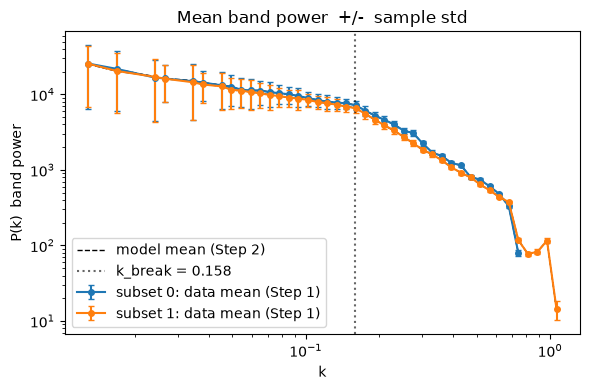

In [2]:
err = np.sqrt(np.diag(pk_cov))

fig, ax = plt.subplots(figsize=(6, 4))
for s in SUBSETS:
    m = subset == s
    ax.errorbar(k_valid[m], pk_mean[m], yerr=err[m], fmt='o-', ms=4, capsize=2, color=f'C{s}',
                label=f'subset {s}: data mean (Step 1)')
    ax.plot(k_valid[m], pk_model[m], '--', color='k', lw=1.0,
            label='model mean (Step 2)' if s == SUBSETS[0] else None)
ax.axvline(k_break, ls=':', color='k', alpha=0.6, label=f'k_break = {k_break:.3f}')
ax.set(xscale='log', yscale='log', xlabel='k', ylabel='P(k)  band power',
       title='Mean band power  +/-  sample std')
ax.legend()
fig.tight_layout()

## 2. Covariance & correlation structure

Left: `log10|C|`. Right: correlation `C_ij / sqrt(C_ii C_jj)`. A near-diagonal
correlation matrix means the band powers are close to independent. The data vector is
subset-major, so the off-diagonal blocks are the correlation between the two subsets, which
image the same sky.

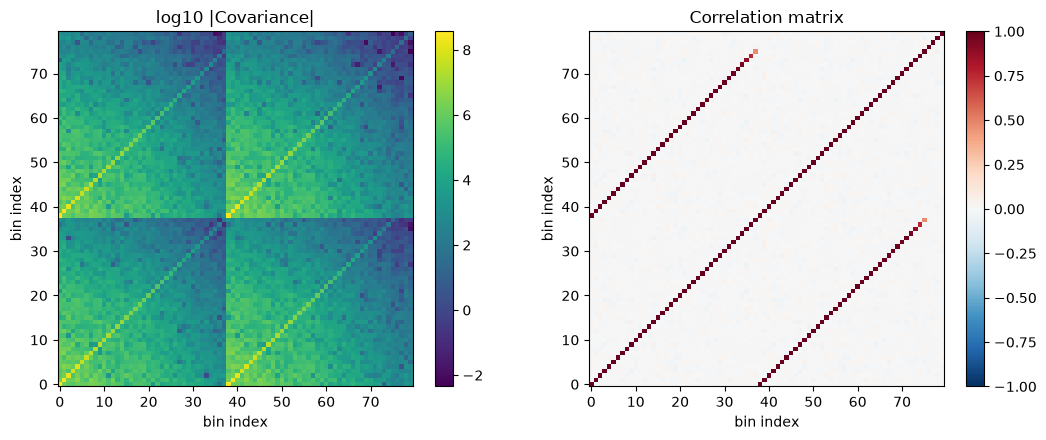

In [3]:
dvec = np.sqrt(np.diag(pk_cov))
corr = pk_cov / np.outer(dvec, dvec)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im0 = axes[0].imshow(np.log10(np.abs(pk_cov) + 1e-30), origin='lower')
axes[0].set_title('log10 |Covariance|')
fig.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(corr, origin='lower', vmin=-1, vmax=1, cmap='RdBu_r')
axes[1].set_title('Correlation matrix')
fig.colorbar(im1, ax=axes[1], fraction=0.046)
for a in axes:
    a.set_xlabel('bin index'); a.set_ylabel('bin index')
fig.tight_layout()

## 3. Invertibility & conditioning, Hartlap factor

eigenvalues   : min = 1.584e+01,  max = 7.218e+08
all positive  : True
condition num : 4.556e+07
max|C inv(C) - I| : 1.47e-12
Hartlap factor    : 0.9838


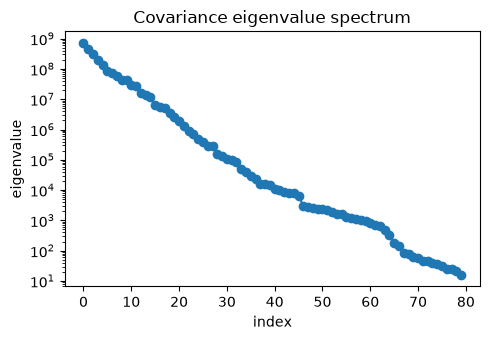

In [4]:
evals = np.linalg.eigvalsh(pk_cov)
hartlap = fa.hartlap_factor(N_REAL, n_valid)
Cinv = np.linalg.inv(pk_cov)
id_err = np.abs(pk_cov @ Cinv - np.eye(n_valid)).max()

print(f'eigenvalues   : min = {evals[0]:.3e},  max = {evals[-1]:.3e}')
print(f'all positive  : {bool((evals > 0).all())}')
print(f'condition num : {evals[-1] / evals[0]:.3e}')
print(f'max|C inv(C) - I| : {id_err:.2e}')
print(f'Hartlap factor    : {hartlap:.4f}')

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogy(evals[::-1], 'o-')
ax.set(xlabel='index', ylabel='eigenvalue', title='Covariance eigenvalue spectrum')
fig.tight_layout()

## 4. Has the covariance converged?

Diagonal errors from growing subsets vs the full-N estimate. Flat = enough realizations.

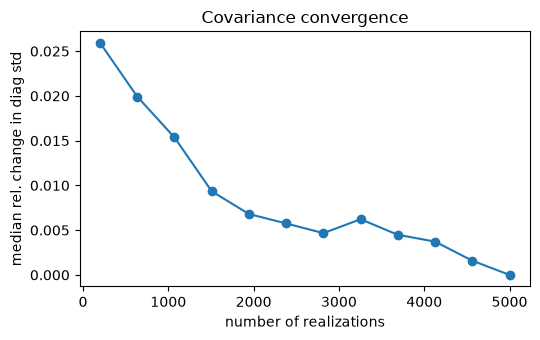

In [5]:
ns = np.unique(np.linspace(200, N_REAL, 12).astype(int))
ref = np.sqrt(np.diag(np.cov(pk_real, rowvar=False)))
relerr = [np.median(np.abs(np.sqrt(np.diag(np.cov(pk_real[:n], rowvar=False))) - ref) / ref)
          for n in ns]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(ns, relerr, 'o-')
ax.set(xlabel='number of realizations', ylabel='median rel. change in diag std',
       title='Covariance convergence')
fig.tight_layout()

## 4b. Are the band powers Gaussian? (chi^2 check)

The Fisher matrix in §6 assumes the band powers `P(k)` follow a **Gaussian**
likelihood. But a band power is an average of `|delta_k|^2` over the modes in its
k-shell, so it is really **chi^2-distributed** and only approaches a Gaussian as
the number of modes grows (central limit theorem). The **few-mode, low-k** bins
are the most non-Gaussian, and there the Gaussian Fisher can slightly
*overestimate* the available information.

We have all `N_REAL` realizations saved, so we can test this directly. Per bin we
measure the **skewness** and **excess kurtosis** across realizations (both 0 for a
Gaussian), convert the skewness to an effective mode count via the chi^2 relation
`skew = 2/sqrt(N_modes)`, and run a D'Agostino-Pearson normality test. The grey
band is the +/-2-sigma sampling scatter expected under exact Gaussianity
(`sqrt(6/N_REAL)`); points well outside it are genuinely non-Gaussian.

subset        k     skew    exkurt   N_modes_eff   normal p
     0    0.013    1.566     3.634             2    0.0e+00  <-- non-Gaussian
     0    0.017    1.444     2.917             2   3.2e-292  <-- non-Gaussian
     0    0.024    1.551     3.617             2    0.0e+00  <-- non-Gaussian
     0    0.026    1.056     1.837             4   8.5e-187  <-- non-Gaussian
     0    0.035    1.286     2.210             2   1.7e-242  <-- non-Gaussian
     0    0.038    0.885     1.355             5   1.1e-139  <-- non-Gaussian
     0    0.045    1.095     1.872             3   2.3e-195  <-- non-Gaussian
     0    0.050    1.130     2.941             3   4.6e-231  <-- non-Gaussian
     0    0.054    0.796     0.779             6   6.3e-106  <-- non-Gaussian
     0    0.059    0.940     1.467             5   1.9e-153  <-- non-Gaussian
     0    0.065    0.752     0.930             7   2.5e-102  <-- non-Gaussian
     0    0.071    0.849     1.286             6   8.3e-131  <-- non-Gaussian
    

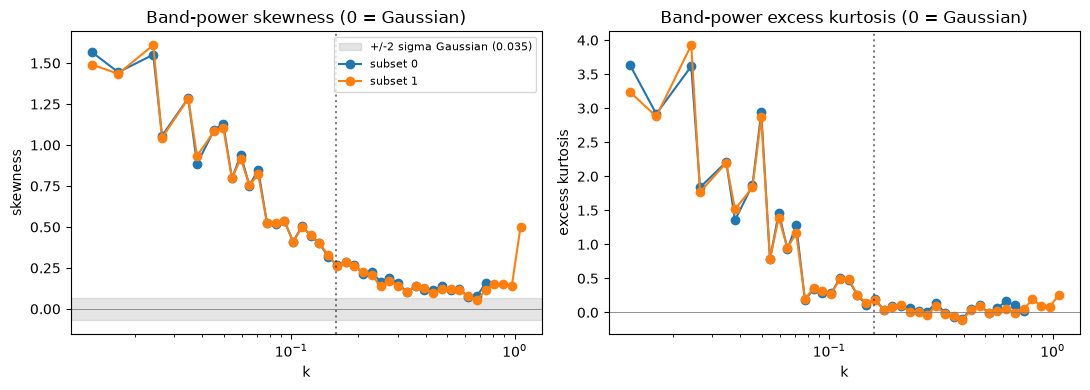

In [6]:
from scipy import stats

# Per-bin distribution of the band power across the N_REAL realizations.
# A band power is an average of |delta_k|^2 over the modes in its k-shell, so it is
# chi^2-distributed and only Gaussian once many modes contribute (CLT). For an
# average of N_modes chi^2_2 variables: skewness = 2/sqrt(N_modes), excess
# kurtosis = 6/N_modes. Few-mode (low-k) bins are the most non-Gaussian.
# Cast to float64: high-k band powers are ~1e-12, so the 4th moment underflows in
# the stored float32 and kurtosis/normaltest return NaN.
pr = pk_real.astype(np.float64)
skew   = stats.skew(pr, axis=0)                      # (n_valid,)  0 if Gaussian
exkurt = stats.kurtosis(pr, axis=0)                  # (n_valid,)  excess; 0 if Gaussian
pval   = np.array([stats.normaltest(pr[:, i]).pvalue for i in range(n_valid)])

skew_scatter = np.sqrt(6.0 / N_REAL)                 # ~1-sigma sampling error on skew
# chi^2 relation skew = 2/sqrt(N_modes); floor at the detection limit (skew_scatter)
N_modes_eff = 4.0 / np.maximum(np.abs(skew), skew_scatter) ** 2

print(f"{'subset':>6s} {'k':>8s} {'skew':>8s} {'exkurt':>9s} {'N_modes_eff':>13s} {'normal p':>10s}")
for i in range(n_valid):
    flag = '  <-- non-Gaussian' if pval[i] < 1e-3 else ''
    print(f'{subset[i]:6d} {k_valid[i]:8.3f} {skew[i]:8.3f} {exkurt[i]:9.3f} '
          f'{N_modes_eff[i]:13.0f} {pval[i]:10.1e}{flag}')
n_bad = int((pval < 1e-3).sum())
print(f'\n{n_bad}/{n_valid} bins reject Gaussianity (p < 1e-3). With N_REAL={N_REAL} the test\n'
      f'detects even tiny departures, so the *magnitude* matters more than the count:\n'
      f'skewness/kurtosis are large at low k (N_modes ~ 1-3, strongly non-Gaussian) and\n'
      f'fall toward high k (N_modes ~ 50-200, nearly Gaussian). The Gaussian Fisher\n'
      f'likelihood is therefore worst at low k.')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].axhspan(-2 * skew_scatter, 2 * skew_scatter, color='gray', alpha=0.2,
              label=f'+/-2 sigma Gaussian ({skew_scatter:.3f})')
for s in SUBSETS:
    ax[0].plot(k_valid[subset == s], skew[subset == s], 'o-', label=f'subset {s}')
ax[0].axhline(0, color='gray', lw=0.6)
ax[0].axvline(k_break, ls=':', color='k', alpha=0.5)
ax[0].set(xscale='log', xlabel='k', ylabel='skewness',
          title='Band-power skewness (0 = Gaussian)')
ax[0].legend(fontsize=8)
for s in SUBSETS:
    ax[1].plot(k_valid[subset == s], exkurt[subset == s], 'o-', label=f'subset {s}')
ax[1].axhline(0, color='gray', lw=0.6)
ax[1].axvline(k_break, ls=':', color='k', alpha=0.5)
ax[1].set(xscale='log', xlabel='k', ylabel='excess kurtosis',
          title='Band-power excess kurtosis (0 = Gaussian)')
fig.tight_layout()

## 5. Band-power gradient dmu/dtheta (Step 2)

One panel per parameter: how the model band power responds to a small change in
that parameter. The **`log10(A)` panel carries an analytic check** — band power is
linear in A, so `dmu/dlog10(A) = ln(10) * mu` (dashed). They should coincide.

log10(A) derivative vs ln(10)*mu  median rel. err : 5.52e-04  (expect ~1e-3)

FD step convergence  ||grad(h/2)-grad(h)|| / ||grad(h)||  (warn if > 1%):
  log10_A        4.133e-04
  n1             3.925e-04
  n2             5.734e-05
  log10_k_break  7.153e-03


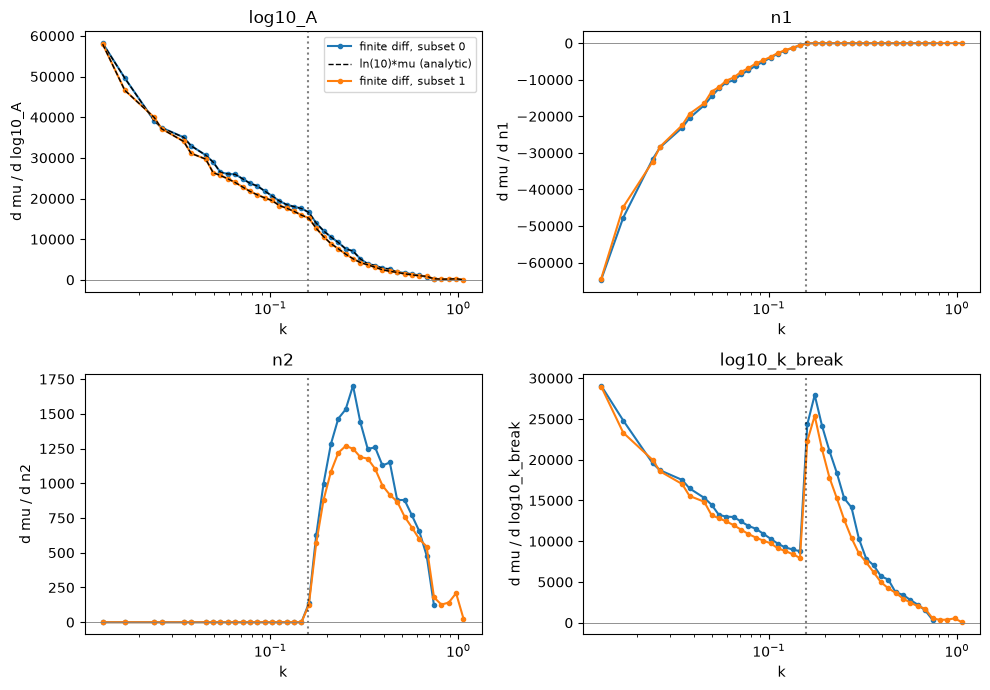

In [7]:
logA_check = np.log(10.0) * pk_model
rel = np.median(np.abs(pk_grad[0] - logA_check) / np.abs(logA_check))
print(f'log10(A) derivative vs ln(10)*mu  median rel. err : {rel:.2e}  (expect ~1e-3)')

# Finite-difference step-size convergence (gradient at h vs h/2), from the generator
# (Step 2, CHECK_FD_CONVERGENCE). A converged central difference changes by << 1%.
if 'fd_convergence' in RES and np.isfinite(RES['fd_convergence']).any():
    print('\nFD step convergence  ||grad(h/2)-grad(h)|| / ||grad(h)||  (warn if > 1%):')
    for nm, fc in zip(NAMES, RES['fd_convergence']):
        flag = '  <-- NOT converged' if fc > 0.01 else ''
        print(f'  {nm:14s} {fc:.3e}{flag}')
else:
    print('\n[note] fd_convergence not in bundle -- re-run fisher_forecast.py '
          'with CHECK_FD_CONVERGENCE=True\n       for the automated h vs h/2 step-size check.')

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, ax in enumerate(axes.ravel()):
    for s in SUBSETS:
        m = subset == s
        ax.plot(k_valid[m], pk_grad[i][m], 'o-', ms=3, color=f'C{s}', label=f'finite diff, subset {s}')
        if i == 0:
            ax.plot(k_valid[m], logA_check[m], 'k--', lw=1,
                    label='ln(10)*mu (analytic)' if s == SUBSETS[0] else None)
    if i == 0:
        ax.legend(fontsize=8)
    ax.axvline(k_break, ls=':', color='k', alpha=0.5)
    ax.axhline(0, color='gray', lw=0.6)
    ax.set(xscale='log', xlabel='k', ylabel=f'd mu / d {NAMES[i]}', title=NAMES[i])
fig.tight_layout()

## 6. Fisher matrix and forecast errors

`F_ij = (dy/dtheta_i)^T (h C^-1) (dy/dtheta_j) [+ term 2] [+ prior]`, then
`param_cov = m1 * F^-1`, `sigma_i = sqrt(param_cov_ii)` — computed by `fisher_assembly.assemble`
with the knobs of **`fisher_config.py`** (shared with the generator).

**`DATA_SPACE`** — data vector `y`:
- `'linear'` — `y = P`. `Cov(P)` is badly conditioned (cond ≈ 3e11 here); `safe_inv` switches to a
  pseudo-inverse, with a warning, above cond = 1e12.
- `'log'` — `y = ln P`. `Cov(ln P)` is well-conditioned (cond ≈ 5e2); the mean-term gradient is the
  Jensen-correct `d<ln P>/dtheta` (`pk_grad_log`).

**`FISHER`** — which terms enter:
- `'mean_only'` — term 1 only.
- `'both_analytic'` — term 1 + `1/2 Tr(C^-1 C,i C^-1 C,j)`, with `dC/dtheta` from the Gaussian
  cosmic-variance model `dC_ij = C_ij (dlnP_i + dlnP_j)`. In log space the derivative of this model
  is identically zero, so there it gives the same forecast as `'mean_only'` (§6c: term 2 ~ 1e-34).
- `'both_numeric'` — term 1 + the same trace with the **re-simulated** `dC/dtheta` (generator
  Step 2b; needs `fisher_forecast.py` run with `FISHER='both_numeric'`).

Two finite-sample corrections, complementary to each other (apply each once):
1. **Hartlap et al. (2007)** debiases the *precision matrix*: `h = (N_s - N_d - 2)/(N_s - 1)`.
2. **Dodelson & Schneider (2013) / Percival et al. (2014)** inflate the *parameter covariance* by
   `m1 = (1 + B(N_d - N_p))/(1 + A + B(N_p + 1))`, with `nu = N_s - N_d`, `A = 2/[(nu-1)(nu-4)]`,
   `B = (nu-2)/[(nu-1)(nu-4)]`.

Here `N_s = 5000`, `N_d` = the kept k-bins of both subsets (printed in §6), `N_p = 4`, so both
corrections are small (percent level).

In [8]:
# Fisher forecast with the knobs of fisher_config.py (imported with fisher_assembly in the setup cell)
DATA_SPACE = fisher_config.DATA_SPACE        # 'linear' or 'log'
FISHER     = fisher_config.FISHER            # 'mean_only' | 'both_analytic' | 'both_numeric'
WITH_PRIOR = fisher_config.WITH_PRIOR        # config.yml pw priors, Gaussian approximation
N_p = len(NAMES)

fc = fa.assemble(RES, DATA_SPACE, FISHER, fisher_config.F_PRIOR if WITH_PRIOR else None)
F, param_cov, sigma, sigma_data = fc['F'], fc['param_cov'], fc['sigma'], fc['sigma_data']
pcorr = param_cov / np.outer(sigma, sigma)

# One code path: with the knobs the bundle was made with, F must equal the stored forecast.
# (Bundles written before the knobs were stored carry no 'data_space' key; they are compared too.)
knobs = (DATA_SPACE, FISHER, WITH_PRIOR)
stored = ((str(RES['data_space']), str(RES['fisher_mode']), bool(RES['with_prior']))
          if 'data_space' in RES else None)
if stored in (None, knobs):
    same = np.allclose(F, RES['fisher_matrix'], rtol=1e-10, atol=0)
    print(f"[check] F {'equals' if same else 'DIFFERS FROM'} fisher_matrix stored in fisher_results.npz")
    assert same or stored is None, 'notebook and generator disagree on the Fisher matrix'
else:
    print(f'[note] knobs {knobs} differ from the stored forecast {stored}; '
          're-run fisher_forecast.py to update the bundle')

print(f'\nDATA_SPACE = {DATA_SPACE!r}    FISHER = {FISHER!r}    WITH_PRIOR = {WITH_PRIOR}')
print(f"cond(C) = {np.linalg.cond(fc['C']):.2e}    Hartlap = {fc['hartlap']:.5f}    "
      f"Percival m1 = {fc['m1']:.5f}")
if FISHER != 'mean_only':
    print(f"term2/term1 (diagonal) = "
          f"{np.array2string(np.diag(fc['F_cov']) / np.diag(fc['F_mean']), precision=3)}")
print('\nFisher matrix F:')
print(np.array_str(F, precision=3, suppress_small=True))
print(f'\nFisher condition number: {np.linalg.cond(F):.3e}\n')
print('Forecast 1-sigma marginalized errors (DS/Percival-corrected):')
for nm, t, s, sd, (lo, hi) in zip(NAMES, true_pw, sigma, sigma_data, fisher_config.PRIOR_BOUNDS):
    print(f'  {nm:14s}  fiducial = {t:+.4f}   sigma = {s:.4f}   '
          f'(data only {sd:.4f}; prior U[{lo:g}, {hi:g}] -> {(hi - lo) / np.sqrt(12):.4f})')
print('\nParameter correlation matrix:')
print(np.array_str(pcorr, precision=3, suppress_small=True))

[check] F equals fisher_matrix stored in fisher_results.npz

DATA_SPACE = 'log'    FISHER = 'both_analytic'    WITH_PRIOR = True
cond(C) = 5.06e+04    Hartlap = 0.98380    Percival m1 = 1.01442
term2/term1 (diagonal) = [1.463e-28 6.441e-27 1.178e-31 1.087e-29]

Fisher matrix F:
[[ 33596.886   -316.872  16313.472  64957.828]
 [  -316.872    114.648    -19.378   -210.239]
 [ 16313.472    -19.378   9159.218  32514.895]
 [ 64957.828   -210.239  32514.895 128378.211]]

Fisher condition number: 3.540e+03

Forecast 1-sigma marginalized errors (DS/Percival-corrected):
  log10_A         fiducial = +1.0000   sigma = 0.0550   (data only 0.0567; prior U[-1, 1.3] -> 0.6640)
  n1              fiducial = -0.5000   sigma = 0.1377   (data only 0.1428; prior U[-1.5, 0.5] -> 0.5774)
  n2              fiducial = -2.0000   sigma = 0.0336   (data only 0.0338; prior U[-3, -1.7] -> 0.3753)
  log10_k_break   fiducial = -0.8000   sigma = 0.0302   (data only 0.0311; prior U[-1.2, -0.5] -> 0.2021)

Parameter corr

## 6b. The two Fisher terms in linear space

The full Gaussian Fisher matrix has **two** terms,

`F_ij = (dmu/dtheta_i)^T C^-1 (dmu/dtheta_j)  +  1/2 Tr(C^-1 C,i C^-1 C,j)`.

`mean_only` keeps the first; `both_*` adds the second. For a power spectrum the
covariance carries cosmic variance (`C_ij ~ P_i P_j`), so in **linear** space term 2
is *not* zero. This cell uses the analytic Gaussian model to show, in linear space and without
the prior, how much the covariance term tightens each `sigma` (≲ 10 % here, largest for `n1`).
§6c then reports the covariance term — analytic *and* re-simulated (when available) — in
**both** linear and log space.

In [9]:
# Standalone LINEAR-space comparison of the two Fisher terms (no prior), independent of the
# DATA_SPACE / FISHER knobs; same fisher_assembly code as §6.
mean_lin = fa.assemble(RES, 'linear', 'mean_only')
both_lin = fa.assemble(RES, 'linear', 'both_analytic')
F_mean_lin, F_cov_lin = both_lin['F_mean'], both_lin['F_cov']
sig_mean, sig_full = mean_lin['sigma'], both_lin['sigma']

print('LINEAR-space Fisher: mean term vs analytic covariance term')
for a, nm in enumerate(NAMES):
    print(f'  {nm:14s}  F_mean={F_mean_lin[a, a]:11.2f}  F_cov={F_cov_lin[a, a]:10.2f}  '
          f'F_cov/F_mean={F_cov_lin[a, a] / F_mean_lin[a, a]:6.2f}')
print()
print(f"{'param':14s} {'sig mean-only':>14s} {'sig both-terms':>15s} {'change':>8s}")
for a, nm in enumerate(NAMES):
    ch = sig_full[a] / sig_mean[a] - 1.0
    print(f'{nm:14s} {sig_mean[a]:14.4f} {sig_full[a]:15.4f} {100 * ch:7.1f}%')

LINEAR-space Fisher: mean term vs analytic covariance term
  log10_A         F_mean=   33760.04  F_cov=    821.94  F_cov/F_mean=  0.02
  n1              F_mean=     124.11  F_cov=    118.43  F_cov/F_mean=  0.95
  n2              F_mean=    9172.14  F_cov=     81.24  F_cov/F_mean=  0.01
  log10_k_break   F_mean=  128739.72  F_cov=   1712.17  F_cov/F_mean=  0.01

param           sig mean-only  sig both-terms   change
log10_A                0.0553          0.0489   -11.7%
n1                     0.1350          0.0974   -27.9%
n2                     0.0338          0.0333    -1.4%
log10_k_break          0.0304          0.0274   -10.1%


## 6c. Covariance term: analytic vs numerical, both spaces

This reports the covariance Fisher term (term2/term1, per parameter) for each
**space** (linear, log) and **method**:
- **analytic** — the Gaussian cosmic-variance model `dC_ij = C_ij(dlnP_i+dlnP_j)`,
  computed in the active space (in log space it transforms via the delta method to an
  algebraic ~0 — *computed*, not assumed).
- **numeric** — the re-simulated `dC/dtheta` from the generator's Step 2b
  (`pk_cov_grad_{lin,log}`), shown only when those arrays are in the bundle (i.e. the
  generator was run with `FISHER='both_numeric'`).

Nothing is forced to zero. The numbers are reported as-is for all four parameters —
interpret them yourself. To populate the numeric rows, run the generator with
`FISHER='both_numeric'` (it adds `pk_cov_grad_{lin,log}` to `fisher_results.npz`).

In [10]:
# Covariance Fisher term (term2 / term1, per parameter) for every space x method (no prior).
# The analytic term is COMPUTED in both spaces; the numeric (re-simulated) term is shown
# whenever its dC/dtheta is in the bundle.
have_numeric = ('pk_cov_grad_lin' in RES) and ('pk_cov_grad_log' in RES)
methods = ['both_analytic'] + (['both_numeric'] if have_numeric else [])
print(f"{'space':7s} {'method':14s}  term2/term1 (diagonal, per parameter)")
print('-' * 78)
for space in ('linear', 'log'):
    for method in methods:
        r = fa.assemble(RES, space, method)
        print(f"{space:7s} {method:14s}  {np.array2string(np.diag(r['F_cov']) / np.diag(r['F_mean']), precision=3)}")
print()
if have_numeric:
    print('Compare analytic vs numeric per space. (In log space the analytic model is\n'
          'identically zero; the numeric value is the empirical re-simulated estimate.)')
else:
    print('Numeric (re-simulated) dC/dtheta not in bundle -- run fisher_forecast.py with\n'
          'FISHER="both_numeric" to add pk_cov_grad_{lin,log} and show the numeric rows.')

space   method          term2/term1 (diagonal, per parameter)
------------------------------------------------------------------------------
linear  both_analytic   [0.024 0.954 0.009 0.013]
log     both_analytic   [1.463e-28 6.441e-27 1.178e-31 1.087e-29]

Numeric (re-simulated) dC/dtheta not in bundle -- run fisher_forecast.py with
FISHER="both_numeric" to add pk_cov_grad_{lin,log} and show the numeric rows.


## 7. Forecast confidence ellipses (corner plot)

Joint 68% (`chi2 = 2.30`) and 95% (`chi2 = 6.17`) ellipses from `param_cov`,
centred on the fiducial parameters. Diagonals show the 1D marginal Gaussians.

Drawn twice: zoomed to +/- 4 sigma, then on prior-bound axes (each panel spans the uniform
prior of `config.yml`), which shows where the forecast sits inside the prior.


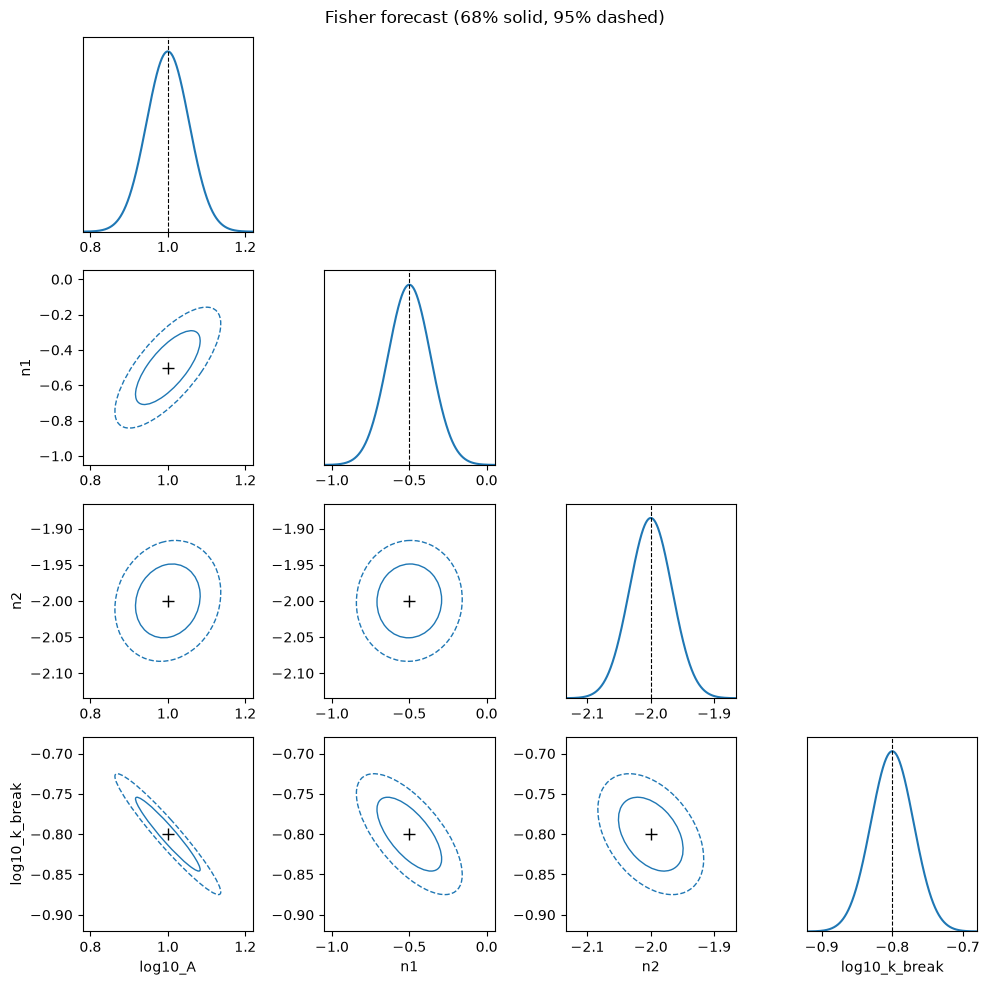

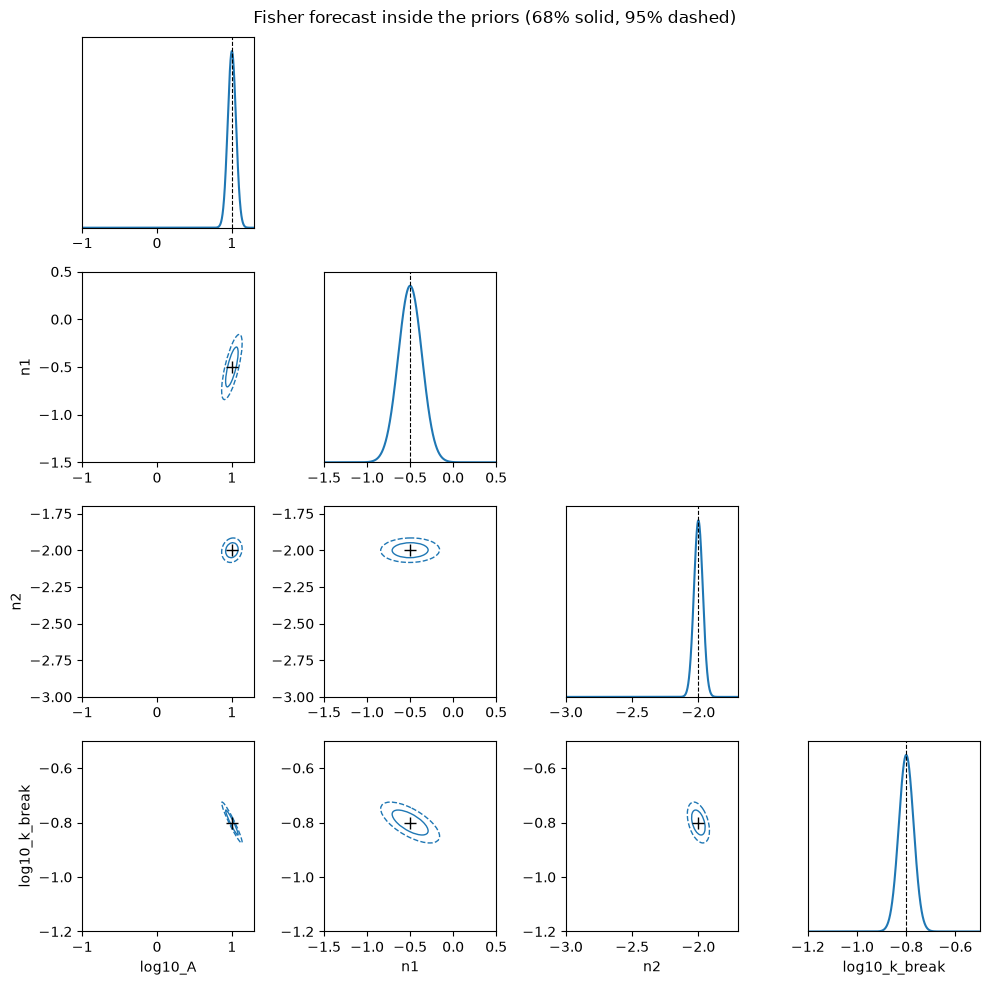

In [11]:
def draw_ellipse(ax, mu2, cov2, chi2, **kw):
    vals, vecs = np.linalg.eigh(cov2)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    width, height = 2.0 * np.sqrt(vals * chi2)
    ax.add_patch(Ellipse(mu2, width, height, angle=angle, fill=False, **kw))


def fisher_corner(ranges, title):
    """Fisher ellipses (68% solid, 95% dashed) and 1D Gaussians around the fiducial.

    ranges: per-parameter (lo, hi) axis limits, or None for +/- 4 sigma around the fiducial.
    """
    P = len(NAMES)
    lims = ranges or [(true_pw[i] - 4 * sigma[i], true_pw[i] + 4 * sigma[i]) for i in range(P)]
    fig, axes = plt.subplots(P, P, figsize=(10, 10))
    for i in range(P):
        for j in range(P):
            ax = axes[i, j]
            if j > i:
                ax.axis('off'); continue
            if i == j:
                x = np.linspace(*lims[i], 2000)
                ax.plot(x, np.exp(-0.5 * ((x - true_pw[i]) / sigma[i]) ** 2))
                ax.axvline(true_pw[i], color='k', ls='--', lw=0.8)
                ax.set_ylim(0, 1.08); ax.set_yticks([])
            else:
                sub = param_cov[np.ix_([j, i], [j, i])]
                mu2 = (true_pw[j], true_pw[i])
                for chi2, ls in [(2.30, '-'), (6.17, '--')]:
                    draw_ellipse(ax, mu2, sub, chi2, edgecolor='C0', ls=ls)
                ax.plot(*mu2, 'k+', ms=8)
                ax.set_ylim(*lims[i])
            ax.set_xlim(*lims[j])
            if i == P - 1:
                ax.set_xlabel(NAMES[j])
            if j == 0 and i > 0:
                ax.set_ylabel(NAMES[i])
    fig.suptitle(title)
    fig.tight_layout()
    return fig


# Zoomed: +/- 4 sigma around the fiducial
_ = fisher_corner(None, 'Fisher forecast (68% solid, 95% dashed)')
# Prior-bound axes: each panel spans the uniform prior of config.yml, showing where the
# forecast sits inside the prior
_ = fisher_corner(fisher_config.PRIOR_BOUNDS, 'Fisher forecast inside the priors (68% solid, 95% dashed)')


## 8. Compare against the SBI posterior (2D)

We have the **SBI posterior samples** from the inference run (neural posterior
estimation — a normalizing flow, *not* MCMC), so instead of transcribing
median +/- errors we load the posterior directly and overlay its **2D contours**
on the Fisher ellipses.

Samples live in the posterior set written by the run:
`output/<RUN_NAME>/samples/posterior/*.npz` (`RUN_NAME` is set in the first code cell;
`run_04` is the run of the current set-up). Each `.npz` is one posterior
draw; we use the `pw` entry — the four power-spectrum parameters
`[log10(A), n1, n2, log10(k_break)]`, in the same order as the Fisher analysis.
(The neighbouring `buffer/` set is the training buffer and is much broader — it
spans the prior — so the posterior set is the right one for this comparison.)

We draw the corner plot twice:
1. **Prior-bound axes** — each panel spans the uniform prior range (from
   `config.yml`), showing where the posterior sits inside the prior. The tight
   Fisher ellipses may spill past these edges.
2. **Dynamic axes** — corner zooms to the posterior. The 1D diagonals are
   rescaled so the tall, narrow Fisher Gaussians are fully visible instead of
   overshooting the top of the panel.

**What to expect:** the Fisher ellipses and the SBI contours should be of
**similar size**, not one strictly inside the other. The Fisher matrix is the
Cramér-Rao bound only *for its own data model*, which differs from what the SBI
sees: it uses fixed known gains (the SBI sees the same band powers of both subsets, plus
`V_ref`), and Gaussian band powers, which is a poor approximation in the low-k bins with only
a few modes. So agreement to ~10-15 %
either way is the expected outcome (the table above: Fisher/SBI = 0.86-1.05).
Where the SBI contour is visibly larger or skewed, that flags non-Gaussianity the
Fisher matrix cannot capture. The SBI posterior should also envelop the fiducial
values if the mock is unbiased.

Loaded 1500 SBI posterior samples from /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_02/samples/posterior
param              true |   SBI med   SBI sig |  Fisher sig |  Fisher/SBI  (med-true)/sig
--------------------------------------------------------------------------------------------
log10_A           1.000 |     0.923     0.047 |       0.055 |        1.18           -1.65
n1               -0.500 |    -0.504     0.122 |       0.138 |        1.13           -0.04
n2               -2.000 |    -1.956     0.033 |       0.034 |        1.01            1.32
log10_k_break    -0.800 |    -0.768     0.026 |       0.030 |        1.14            1.21


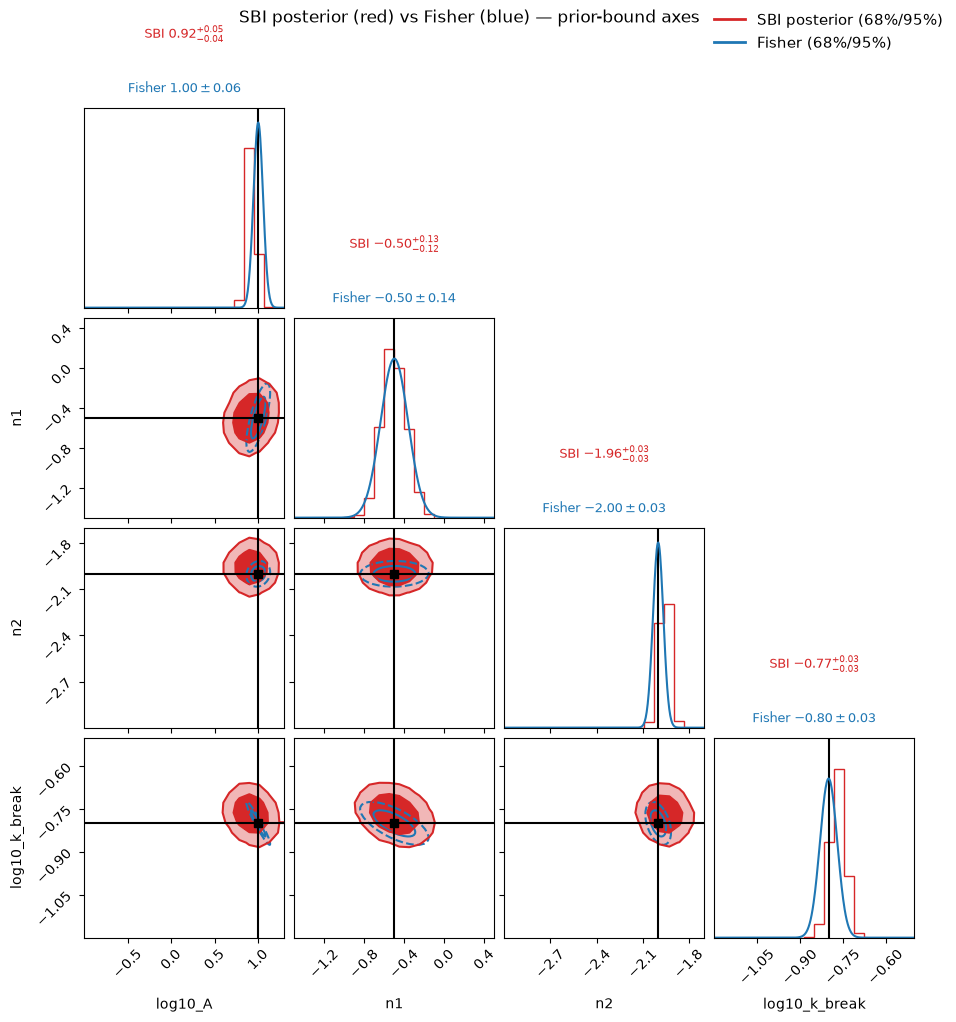

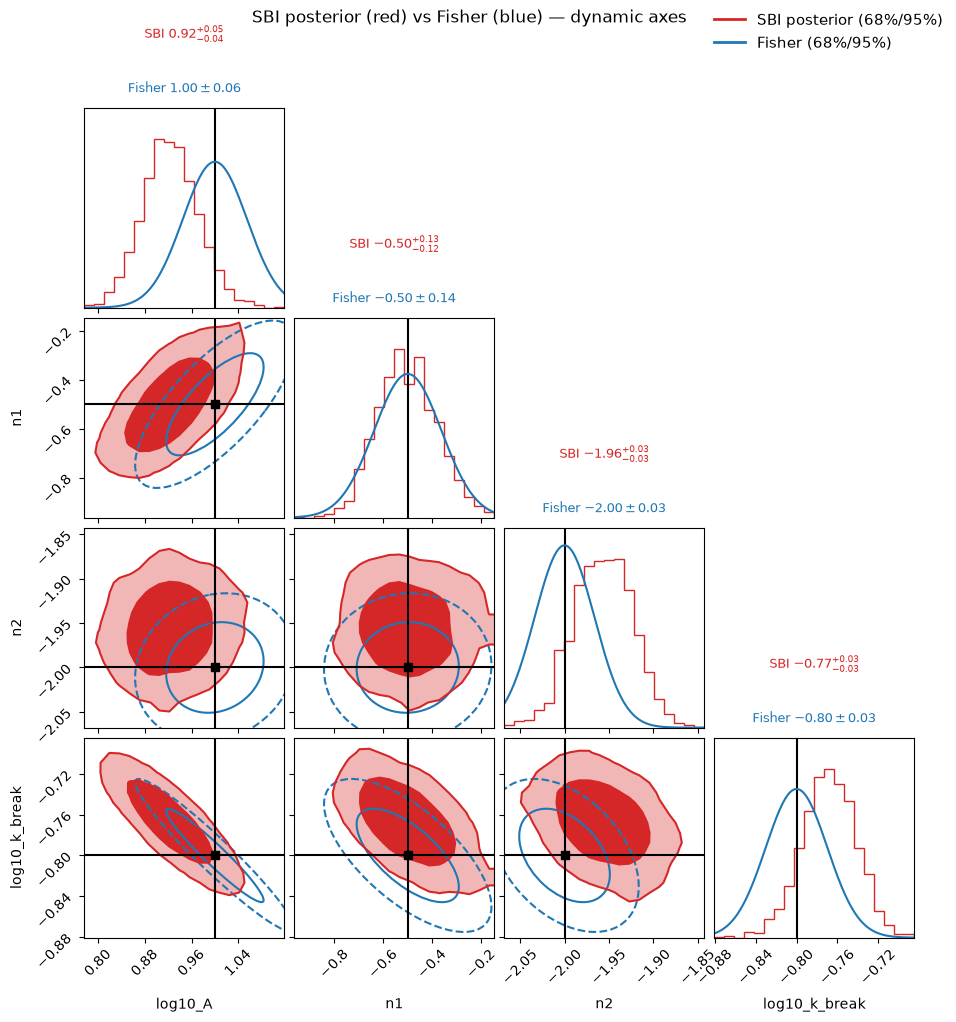

In [12]:
import glob
import corner
from matplotlib.lines import Line2D

# --- load the SBI posterior samples written by the run ---
import yaml
run_path = Path(RUN_NAME) if Path(RUN_NAME).exists() else HERE.parent / 'output' / RUN_NAME
# only compare with a run of the current set-up (graph / buffer / sampling as config.yml),
# the same guard as notebooks/plot_posteriors.ipynb
_run_cfg = yaml.safe_load((run_path / 'config.yml').read_text())
_cur_cfg = yaml.safe_load((HERE.parent / 'config.yml').read_text())
for _key in ('graph', 'buffer', 'sample'):
    assert _run_cfg[_key] == _cur_cfg[_key], \
        f"{run_path.name}: '{_key}' differs from config.yml -- not a run of the current set-up"
post_dir = run_path / 'samples' / 'posterior'
files = sorted(glob.glob(str(post_dir / '*.npz')))
sbi_samples = np.array([np.load(f)['pw'] for f in files])   # (N_samp, 4)
print(f'Loaded {sbi_samples.shape[0]} SBI posterior samples from {post_dir}')

# uniform prior bounds for pw, read from config.yml (graph.pw simulator) by fisher_config
PRIOR_BOUNDS = fisher_config.PRIOR_BOUNDS

# --- summarize: median and 16/84 percentile half-widths (per parameter) ---
q16, q50, q84 = np.percentile(sbi_samples, [16, 50, 84], axis=0)
sbi = {nm: (q50[i], q84[i] - q50[i], q50[i] - q16[i]) for i, nm in enumerate(NAMES)}

# --- comparison table (SBI stats come from the posterior samples themselves) ---
print(f"{'param':14s} {'true':>8s} | {'SBI med':>9s} {'SBI sig':>9s} | "
      f"{'Fisher sig':>11s} | {'Fisher/SBI':>11s} {'(med-true)/sig':>15s}")
print('-' * 92)
for i, nm in enumerate(NAMES):
    med, ep, em = sbi[nm]
    sbi_sig = 0.5 * (ep + em)               # symmetrized SBI error
    fisher_sig = sigma[i]
    pull = (med - true_pw[i]) / sbi_sig     # offset of SBI median from fiducial
    print(f'{nm:14s} {true_pw[i]:8.3f} | {med:9.3f} {sbi_sig:9.3f} | '
          f'{fisher_sig:11.3f} | {fisher_sig / sbi_sig:11.2f} {pull:15.2f}')




def sbi_vs_fisher_corner(rng, title):
    """Corner plot of the SBI posterior with Fisher ellipses/Gaussians overlaid.

    rng: per-parameter (lo, hi) axis ranges passed to corner, or None for the
         data-driven (dynamic) ranges corner picks automatically.
    Each diagonal is titled with the SBI median +/- (16/84) error (red) and the
    Fisher fiducial +/- sigma (blue).
    """
    P = len(NAMES)
    fig = corner.corner(
        sbi_samples, labels=NAMES, truths=list(true_pw), range=rng,
        levels=(0.68, 0.95), color='C3', truth_color='k',
        plot_datapoints=False, fill_contours=True, smooth=1.0,
        hist_kwargs={'density': True},
    )
    axes = np.array(fig.axes).reshape((P, P))
    for i in range(P):
        # diagonal: overlay the normalized Fisher Gaussian, then rescale y so the
        # (tall, narrow) Fisher peak is fully inside the panel instead of clipping.
        ax = axes[i, i]
        xlo, xhi = ax.get_xlim()
        x = np.linspace(xlo, xhi, 400)
        g = np.exp(-0.5 * ((x - true_pw[i]) / sigma[i]) ** 2) / (np.sqrt(2 * np.pi) * sigma[i])
        ax.plot(x, g, 'C0-', lw=1.5)
        peak = 1.0 / (np.sqrt(2 * np.pi) * sigma[i])     # true Gaussian peak height
        ax.set_ylim(0, max(ax.get_ylim()[1], peak) * 1.08)
        # numbers on top: SBI median +/- 16/84 (red), Fisher fiducial +/- sigma (blue)
        med, ep, em = sbi[NAMES[i]]
        ax.text(0.5, 1.32, rf'SBI ${med:.2f}^{{+{ep:.2f}}}_{{-{em:.2f}}}$',
                transform=ax.transAxes, ha='center', va='bottom',
                color='C3', fontsize=9)
        ax.text(0.5, 1.06, rf'Fisher ${true_pw[i]:.2f}\pm{sigma[i]:.2f}$',
                transform=ax.transAxes, ha='center', va='bottom',
                color='C0', fontsize=9)
        # off-diagonal (lower triangle): 68% / 95% Fisher ellipses
        for j in range(i):
            ax = axes[i, j]
            sub = param_cov[np.ix_([j, i], [j, i])]
            mu2 = (true_pw[j], true_pw[i])
            for chi2, ls in [(2.30, '-'), (6.17, '--')]:
                draw_ellipse(ax, mu2, sub, chi2, edgecolor='C0', ls=ls, lw=1.5)
    fig.legend(
        handles=[Line2D([0], [0], color='C3', lw=2, label='SBI posterior (68%/95%)'),
                 Line2D([0], [0], color='C0', lw=2, label='Fisher (68%/95%)')],
        loc='upper right', frameon=False, fontsize=11,
    )
    fig.suptitle(title, y=1.06)
    return fig


# Plot 1 — axes fixed to the uniform prior bounds: shows where the posterior sits
# within the prior. The tight Fisher ellipses can spill past these edges.
_ = sbi_vs_fisher_corner(PRIOR_BOUNDS,
                          'SBI posterior (red) vs Fisher (blue) — prior-bound axes')

# Plot 2 — dynamic axes: corner zooms to the posterior; diagonals rescaled so the
# Fisher Gaussians are fully visible rather than overshooting the top.
_ = sbi_vs_fisher_corner(None,
                          'SBI posterior (red) vs Fisher (blue) — dynamic axes')

### Notes / caveats

Forecast settings are in **`fisher_config.py`** (`DATA_SPACE`, `FISHER`), shared by
the notebook and the generator; all six combinations are supported and every term is
computed (§6). This is a **low-mode-count** regime (§4b: effective modes per bin run
from ~1 at low k to a few hundred at high k), which stresses the two standard Fisher
approximations:

- **Gaussian likelihood.** Band powers are chi^2, not Gaussian (§4b). Working with
  `y = ln P` (`DATA_SPACE='log'`) makes the distribution far more symmetric, so the
  Gaussian Fisher/likelihood is more accurate. It is also far better conditioned
  (`Cov(ln P)` cond ≈ 5e2 vs `Cov(P)` ≈ 3e11 here).
- **Mean-only vs covariance term.** `FISHER='mean_only'` keeps term 1 only;
  `both_analytic` / `both_numeric` add term 2 (§6, §6b, §6c report its size in each
  space and by method — no term is assumed zero).

The §8 **SBI posterior** makes none of these approximations (no Gaussian likelihood,
no fixed covariance) and is the most trustworthy error; the Fisher ellipses are the
Gaussian lower-bound reference.

Bookkeeping (small, exact corrections):

- The inverse covariance is **Hartlap-debiased** (`hartlap * C^-1`). Do not apply it twice.
- The parameter covariance carries the **Dodelson-Schneider / Percival `m1`** factor
  (§6), complementary to Hartlap (precision matrix vs parameter covariance). Apply
  both, neither twice. It only affects the Fisher side; the SBI posterior never uses
  this sample covariance.
- Near-singular covariances are handled by `safe_inv` (pseudo-inverse fallback above
  `cond > 1e12`); the gradient step size is checked at h vs h/2 in the generator (§5).
- **Fixed gains.** The forecast holds the gains at their true values; the SBI posterior marginalises
  over the 212 gain parameters through `V_ref`. Both use the same data, the band powers of the two
  subsets. With `NOISE_STD = 0` the gains are exactly recoverable from `V_ref`, so
  the two are expected to agree; with noise on, the SBI errors should be the larger.